# 1.3 The SIR & SIRS Model

For most real infections (measles, influenza, COVID-19), people who recover do **not** immediately become susceptible again—they develop **immunity**.

We add a third compartment to represent immune individuals:

- **$S$ (`u[1]`)** — **Susceptible** population
- **$I$ (`u[2]`)** — **Infectious** population
- **$R$ (`u[3]`)** — **Recovered** (immune) population

## From SIS to SIR & SIRS

![SIR and SIRS compartmental model](../images/sir-sirs-diagram.svg)

Adding the **Recovered ($R$)** compartment—and an optional rate of **waning immunity ($\epsilon$)**—gives three ODEs:

$$
\begin{aligned}
\frac{dS}{dt} &= -r \beta S I + \epsilon R \\
\frac{dI}{dt} &= r \beta S I - \gamma I \\
\frac{dR}{dt} &= \gamma I - \epsilon R
\end{aligned}
$$

- When **$\epsilon = 0$**, immunity is lifelong (**SIR model**) — the classic single-wave epidemic!
- When **$\epsilon > 0$**, recovered people gradually lose immunity and return to $S$ (**SIRS model**) — allowing **multiple waves** or an endemic state.

## Step 1: Load Julia Packages

In [ ]:
using DifferentialEquations
using Plots
println("Ready for SIR / SIRS simulations!")

Ready for SIR / SIRS simulations!

## Step 2: Run the Baseline SIR Simulation

Notice that `epsilon = 0.0`, so recovered individuals keep lifelong immunity. Run the cell below to watch the classic epidemic wave rise, peak, and subside as the susceptible pool drops below the herd-immunity threshold!

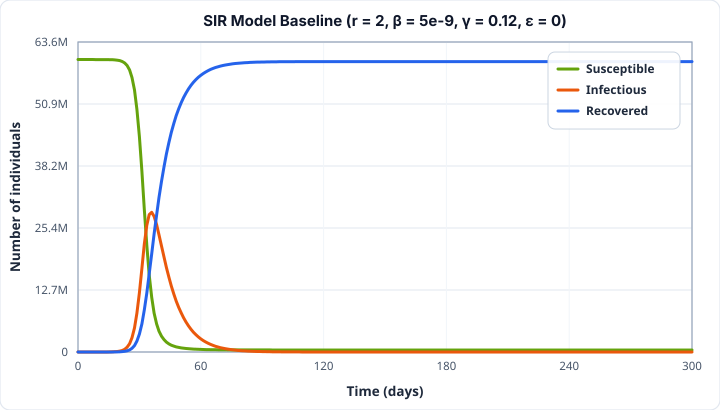

In [ ]:
# Define parameters
r       = 2       # Number of contacts per unit time
beta    = 5e-9    # Probability of disease transmission
gamma   = 0.12    # Recovery rate (try 0.07 as well)
epsilon = 0.0     # Loss of immunity rate (try 1/60 for ~60-day immunity!)
N       = 6e7     # Population size (N = S + I + R)

# Define differential equations
function SIR!(du, u, p, t)
    r, beta, gamma, epsilon = p
    du[1] = -r * beta * u[1] * u[2] + epsilon * u[3]   # dS/dt
    du[2] =  r * beta * u[1] * u[2] - gamma * u[2]     # dI/dt
    du[3] =  gamma * u[2] - epsilon * u[3]             # dR/dt
end

# Initial conditions, parameters, and time span
u0    = [N, 10.0, 0.0]
p     = [r, beta, gamma, epsilon]
tspan = (0.0, 300.0)

# Solve ODE & plot
prob = ODEProblem(SIR!, u0, tspan, p)
sol  = solve(prob)

plot(sol, lw=3, label=["Susceptible" "Infectious" "Recovered"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="SIR / SIRS Model (r=$r, β=$beta, γ=$gamma, ε=$(round(epsilon, digits=4)))",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)

## Challenge 1: What Happens If the Loss of Immunity Increases?

Many respiratory viruses (such as seasonal coronaviruses and influenza) do **not** provide permanent immunity.

**Your task:** Change `epsilon` from `0.0` to `1/60` (meaning immunity lasts ~60 days on average), and also try `1/20`. What happens to the orange **Infectious** curve over 300 days?

In [ ]:
# Challenge 1 starter code — edit epsilon below and press Shift + Enter!
r       = 2
beta    = 5e-9
gamma   = 0.12
epsilon = 0.0     # <-- Try changing this to 1/60 or 1/20!
N       = 6e7

u0    = [N, 10.0, 0.0]
p     = [r, beta, gamma, epsilon]
tspan = (0.0, 300.0)

prob = ODEProblem(SIR!, u0, tspan, p)
sol  = solve(prob)

plot(sol, lw=3, label=["Susceptible" "Infectious" "Recovered"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="SIRS Challenge 1 (ε = $(round(epsilon, digits=4)))",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)

````{admonition} Hint — Challenge 1
:class: tip, dropdown

Change `epsilon = 0.0` to `epsilon = 1/60`. Because recovered people gradually feed back into the Susceptible ($S$) compartment, watch whether the Infectious ($I$) curve drops back to zero or bounces back into **secondary waves**!
````

````{admonition} Reveal Solution — Challenge 1
:class: note, dropdown

When immunity wanes (`epsilon = 1/60`), the epidemic no longer dies out after the first peak! Instead, replenished susceptibles trigger **damped recurrent waves** that eventually settle into a persistent **endemic equilibrium**. Increasing `epsilon` further (e.g. `1/20`) produces faster, higher secondary waves and a larger endemic infected pool.

```julia
r       = 2
beta    = 5e-9
gamma   = 0.12
epsilon = 1/60    # Average immunity duration ~60 days
N       = 6e7

u0    = [N, 10.0, 0.0]
p     = [r, beta, gamma, epsilon]
tspan = (0.0, 300.0)

prob = ODEProblem(SIR!, u0, tspan, p)
sol  = solve(prob)

plot(sol, lw=3, label=["Susceptible" "Infectious" "Recovered"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="SIRS Solution (ε = 1/60)",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)
```
````

## Challenge 2: "Flattening the Curve" — Reducing Transmission or Contacts

During a pandemic, hospitals care enormously about the **peak height** of the orange **Infectious** curve (how many people are sick *at the same time*).

**Your task:** Keep `epsilon = 0.0` and edit `r` or `beta` in the cell below (e.g. reduce `r` from `2` to `1`, or `beta` from `5e-9` to `2.5e-9`). Notice both the **height** and **timing** of the epidemic peak, and how many people remain uninfected (`Susceptible`) at the end!

In [ ]:
# Challenge 2 starter code — edit r or beta to flatten the curve!
r       = 2       # <-- Try r = 1 (50% fewer contacts)
beta    = 5e-9    # <-- Or beta = 2.5e-9 (50% lower transmission probability)
gamma   = 0.12
epsilon = 0.0
N       = 6e7

u0    = [N, 10.0, 0.0]
p     = [r, beta, gamma, epsilon]
tspan = (0.0, 300.0)

prob = ODEProblem(SIR!, u0, tspan, p)
sol  = solve(prob)

peak_infected = round(Int, maximum(sol[2, :]))
println("Peak simultaneously infectious: ", peak_infected)

plot(sol, lw=3, label=["Susceptible" "Infectious" "Recovered"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="SIR Challenge 2 (r=$r, β=$beta)",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)

````{admonition} Hint — Challenge 2
:class: tip, dropdown

Compare `peak_infected` printed above the plot when `r = 2` vs `r = 1` (or `beta = 2.5e-9`).
Does halving transmission halve the peak, or reduce it by **even more** than half?
````

````{admonition} Reveal Solution — Challenge 2
:class: note, dropdown

Halving contacts (`r = 1`, or `beta = 2.5e-9`) dramatically **flattens and delays** the peak:
- With `r = 2`, the peak reaches nearly **29 million** simultaneously infectious people around day 35!
- With `r = 1`, the peak drops by more than half (to ~**14 million**) AND arrives much later (around day 85)—giving healthcare systems far more time to prepare, while also leaving more people completely uninfected at day 300!

```julia
r       = 1       # 50% fewer contacts
beta    = 5e-9
gamma   = 0.12
epsilon = 0.0
N       = 6e7

u0    = [N, 10.0, 0.0]
p     = [r, beta, gamma, epsilon]
tspan = (0.0, 300.0)

prob = ODEProblem(SIR!, u0, tspan, p)
sol  = solve(prob)

peak_infected = round(Int, maximum(sol[2, :]))
println("Peak simultaneously infectious: ", peak_infected)

plot(sol, lw=3, label=["Susceptible" "Infectious" "Recovered"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="SIR Flattened Curve (r=$r, β=$beta)",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)
```
````

---

**Next:** What happens over longer timescales when **births and deaths** continually reshape the population? Continue to [**1.4 Endemic SIR: Births & Deaths**](04-endemic-sir-model.ipynb).